In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error
from sklearn.preprocessing import StandardScaler


In [20]:
housing = fetch_california_housing(as_frame = True)
df = housing.frame

In [21]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [22]:
df.shape

(20640, 9)

In [23]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

In [24]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

In [25]:
X.shape

(20640, 8)

In [26]:
y.shape

(20640,)

In [27]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [29]:
X_train.shape


(16512, 8)

In [30]:
X_test.shape

(4128, 8)

In [31]:
y_train.shape

(16512,)

In [32]:
y_test.shape

(4128,)

In [34]:
model = LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [35]:
y_pred = model.predict(X_test)

In [36]:
print(y_pred[:5])

[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]


In [37]:
print(y_test.iloc[:5].values)

[0.477   0.458   5.00001 2.186   2.78   ]


In [39]:
mean_absolute_error(y_test,y_pred)

0.5332001304956554

In [41]:
mean_squared_error(y_test,y_pred)

0.555891598695244

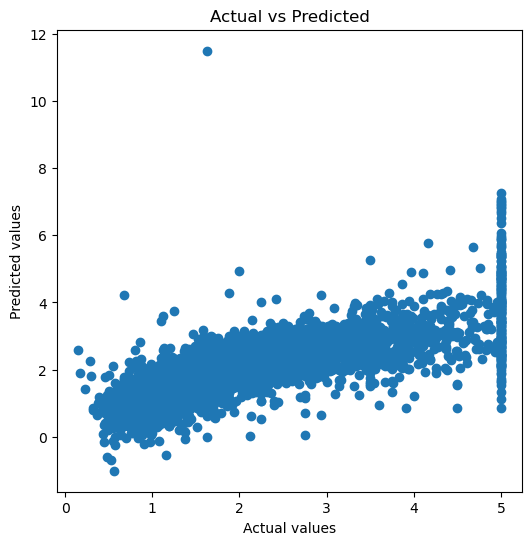

In [43]:

plt.figure(figsize=(6, 6))
plt.scatter(y_test,y_pred)
plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual vs Predicted")
plt.show()

In [46]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge

In [47]:
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
        )

In [48]:
ridge_model.fit(X_train,y_train)

Pipeline(steps=[('standardscaler', StandardScaler()), ('ridge', Ridge())])

In [49]:
ridge_model_pred = ridge_model.predict(X_test)

In [50]:
mean_absolute_error(y_test,ridge_model_pred)

0.5331931195789735

In [51]:
mean_squared_error(y_test,ridge_model_pred)

0.5558548589435967

In [52]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=123)

In [54]:
ridge_pipeline = make_pipeline(
    StandardScaler(),
    Ridge()
)


In [62]:
param_grid = {
    "ridge__alpha":[0.01,0.1,1,10,100]
}

In [63]:
from sklearn.model_selection import GridSearchCV

In [64]:
grid_search = GridSearchCV(
    estimator = ridge_pipeline,
    param_grid = param_grid,
    scoring = "neg_mean_absolute_error",
    cv = 5,
    n_jobs = -1
)

In [65]:
grid_search.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('standardscaler', StandardScaler()),
                                       ('ridge', Ridge())]),
             n_jobs=-1, param_grid={'ridge__alpha': [0.01, 0.1, 1, 10, 100]},
             scoring='neg_mean_absolute_error')

In [66]:
print("Best alpha:",grid_search.best_params_)

Best alpha: {'ridge__alpha': 10}


In [67]:
print("Best CV MAE:",-grid_search.best_score_)

Best CV MAE: 0.5354312194371676


In [68]:
best_model = grid_search.best_estimator_


In [69]:
y_test_pred = best_model.predict(X_test)

In [70]:
test_mae = mean_absolute_error(y_test, y_test_pred)
print("Final Test MAE:", test_mae)

Final Test MAE: 0.5255141524829945


In [71]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_test_pred
})

results["Error"] = results["Actual"] - results["Predicted"]
results["Absolute_Error"] = results["Error"].abs()

results.head()

,Actual,Predicted,Error,Absolute_Error
19121,1.516,2.375729,-0.859729,0.859729
20019,0.992,1.438780,-0.446780,0.446780
15104,1.345,2.035403,-0.690403,0.690403
3720,2.317,1.606954,0.710046,0.710046
8938,4.629,2.654360,1.974640,1.974640


In [72]:
results.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

,Actual,Predicted,Error,Absolute_Error
10448,5.00001,1.184465,3.815545,3.815545
12389,5.00001,1.310391,3.689619,3.689619
1913,4.37500,0.996221,3.378779,3.378779
15615,5.00001,1.756392,3.243618,3.243618
14460,4.88900,1.645411,3.243589,3.243589
16828,2.81000,5.985288,-3.175288,3.175288
8859,5.00001,1.912699,3.087311,3.087311
17067,5.00001,2.043410,2.956600,2.956600
8922,4.50000,1.548662,2.951338,2.951338
4740,5.00001,2.059897,2.940113,2.940113


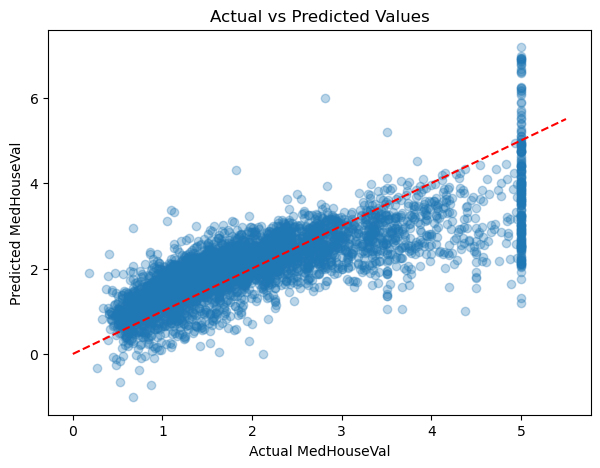

In [73]:
plt.figure(figsize=(7, 5))

plt.scatter(
    results["Actual"],
    results["Predicted"],
    alpha=0.3
)

plt.plot([0, 5.5], [0, 5.5], "r--")

plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.title("Actual vs Predicted Values")

plt.show()